# 05 – Val av metod och tolkning av modellen

Den här notebooken sammanfattar jämförelsen mellan K-means (`02_kmeans.ipynb`), LDA (`03_lda.ipynb`) och HDBSCAN (`04_hdbscan.ipynb`), motiverar valet av slutlig metod och tolkar den valda modellen med ett beslutsträd.

**Upplägg:**
1. Val av metod
2. Tolkning av klustren med beslutsträd
3. Slutsatser

## 1. Val av metod: K-means

Metoderna bedömdes utifrån projektets affärsfråga: *kan vi hitta naturliga ärendetyper i klagomålstexter utan manuell märkning, och vilka ärendetyper leder oftare till att kunden får hjälp?* Resultatet ska också kunna användas i en app där nya klagomål sorteras in.

| Kriterium | Bäst | Motivering |
|---|---|---|
| Hittar nya ärendetyper utöver produktindelningen | **K-means** | Lägst likhet med CFPB:s produkter (ARI ≈ 0,17 mot 0,59 för HDBSCAN). HDBSCAN återskapar till stor del kategorier som redan finns. |
| Samband med om kunden får hjälp | HDBSCAN | Högst Cramér's V (0,207 mot 0,183), men delvis för att den liknar produktindelningen. Alla tre metoder visar samma mönster. |
| Användbart i praktiken | **K-means** | Alla klagomål får en ärendetyp och nya klagomål kan sorteras in direkt. HDBSCAN lämnar 36 % utan ärendetyp och kan inte placera nya texter i befintliga kluster. |
| Tolkningsbarhet | K-means / HDBSCAN | Alla grupper går att namnge (LDA: 12 av 14). |

**K-means valdes** eftersom den bäst besvarar affärsfrågan: den hittar flest ärendetyper som går på tvärs av CFPB:s produkter, ger alla klagomål en ärendetyp och fungerar i en app.

**Vad som uppoffras:**
- **Ett heterogent kluster.** *Bristande ärendehantering* (21 %) samlar klagomål som främst beskriver ett utdraget förlopp. LDA och HDBSCAN visar att klustret innehåller flera ärendetyper, t.ex. tvister med handlare, stängda konton, bonusar och kundservice.
- **Något svagare samband med utfallet** än HDBSCAN.
- **Ingen bild av blandade klagomål.** K-means placerar varje klagomål i exakt en grupp, trots att LDA visar att de flesta klagomål handlar om flera saker.

**Möjlig förbättring:** dela upp *Bristande ärendehantering* i ett andra steg, t.ex. genom att klustra enbart det klustret igen.

## 2. Tolkning av klustren med beslutsträd

K-means grupperar klagomål utifrån hundra komprimerade dimensioner, vilket är svårt att förklara. För att göra modellen begriplig tränas ett **beslutsträd** som försöker förutsäga vilket kluster ett klagomål hamnar i, utifrån vilka ord det innehåller.

Enkelt förklarat: beslutsträdet ställer en serie ja/nej-frågor om texten, t.ex. *"Innehåller texten ordet 'escrow'?"*, tills det kan säga vilken ärendetyp klagomålet tillhör. De ord som trädet använder mest är de som avgör vilket kluster ett klagomål hamnar i (**feature importance**).

Trädet är en **förklaringsmodell**, inte en ersättning för K-means. Ju bättre det träffar, desto bättre beskriver orden hur K-means har grupperat klagomålen.

Data delas i träningsdata (80 %) och testdata (20 %), stratifierat per kluster. Trädets djup begränsas så att det förblir tolkningsbart.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS

df = pd.read_parquet("../data/complaints_kmeans.parquet")
print("Antal klagomål:", len(df))

foretagsnamn = {
    "wells", "fargo", "chase", "jpmorgan", "paypal", "capital", "affirm",
    "mohela", "navient", "nelnet", "citi", "citibank", "synchrony",
    "amex", "barclays", "coinbase", "santander", "ally", "truist",
    "america", "venmo",
}
klagomalsord = {
    "told", "called", "received", "did", "company", "consumer",
    "information", "said", "asked", "stated", "contacted",
}
stoppord = list(ENGLISH_STOP_WORDS | foretagsnamn | klagomalsord)

vec = TfidfVectorizer(stop_words=stoppord, min_df=20, max_df=0.5)
X = vec.fit_transform(df["text_clean"])
ord_lista = vec.get_feature_names_out()
y = df["arendetyp"]

print("Matrisens storlek:", X.shape)

Antal klagomål: 101373
Matrisens storlek: (101373, 9189)


In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

trad = DecisionTreeClassifier(max_depth=10, min_samples_leaf=50, random_state=42)
trad.fit(X_train, y_train)

print(f"Träffsäkerhet, träningsdata: {accuracy_score(y_train, trad.predict(X_train)):.1%}")
print(f"Träffsäkerhet, testdata:     {accuracy_score(y_test, trad.predict(X_test)):.1%}")
print()
print(classification_report(y_test, trad.predict(X_test)))

Träffsäkerhet, träningsdata: 74.2%
Träffsäkerhet, testdata:     73.8%

                                               precision    recall  f1-score   support

                  Avgifter och övertrassering       0.84      0.63      0.72       655
             Bedrägeri och stängda bankkonton       0.81      0.82      0.82      1742
                   Billån och återtagna bilar       0.81      0.24      0.37       683
                  Bolån: escrow och utmätning       0.82      0.82      0.82      1200
                    Bristande ärendehantering       0.61      0.82      0.70      4284
            Checkar och spärrade insättningar       0.89      0.79      0.84       824
Felaktig kreditupplysning och identitetsstöld       0.57      0.73      0.64      1541
                      Ifrågasatta inkassokrav       0.88      0.87      0.88      1820
                Inkasso på kreditupplysningen       0.79      0.39      0.52       741
          Juridiska hänvisningar och mallbrev       0.86  

**Resultat – beslutsträdet:**

- Trädet förutsäger rätt kluster för **73,8 %** av klagomålen i testdata (74,2 % i träningsdata). Den lilla skillnaden visar att trädet inte är överanpassat. Ord förklarar alltså tre fjärdedelar av hur K-means har grupperat klagomålen.
- **Bäst förklarade kluster** är *Ifrågasatta inkassokrav* (F1 0,88), *Obehöriga kortdebiteringar* (0,85), *Checkar och spärrade insättningar* (0,84) samt *Bolån* och *Bedrägeri* (0,82). De känns igen på tydliga nyckelord.
- **Bristande ärendehantering** har hög recall (0,82) men låg precision (0,61). Trädet placerar många oklara texter där, även sådana som K-means lade i andra kluster. Klustret saknar tydliga nyckelord och fungerar som "övrigt", vilket bekräftar tidigare analys.
- ***Juridiska hänvisningar*** **och** ***Billån*** **missas ofta** (recall 0,22 och 0,24) men förutsägs med hög precision (0,86 och 0,81). En trolig förklaring är att dessa kluster kännetecknas av kombinationer av många ord, vilket ett träd med begränsat djup inte fångar.

### Vilka ord avgör vilket kluster ett klagomål hamnar i?

**Feature importance** visar hur mycket varje ord bidrar till trädets beslut, sammanlagt för alla kluster. Därefter visas trädets första nivåer som läsbara regler.

Siffrorna i reglerna är TF-IDF-värden. En regel som `escrow <= 0.02` betyder i praktiken *"ordet escrow förekommer inte, eller nästan inte, i texten"*.

Antal ord som trädet använder: 32 av 9189


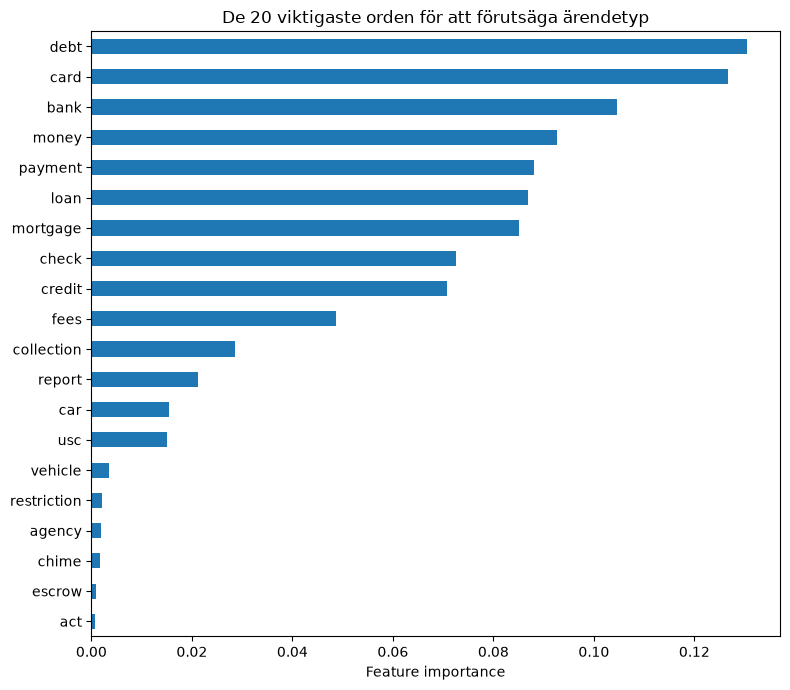

In [3]:
viktighet = pd.Series(trad.feature_importances_, index=ord_lista).sort_values(ascending=False)

print("Antal ord som trädet använder:", (viktighet > 0).sum(), "av", len(ord_lista))

fig, ax = plt.subplots(figsize=(8, 7))
viktighet.head(20).sort_values().plot.barh(ax=ax, color="tab:blue")
ax.set_title("De 20 viktigaste orden för att förutsäga ärendetyp")
ax.set_xlabel("Feature importance")
plt.tight_layout()
plt.show()

In [4]:
from sklearn.tree import export_text

print(export_text(trad, feature_names=list(ord_lista), max_depth=4))

|--- debt <= 0.12
|   |--- card <= 0.11
|   |   |--- bank <= 0.10
|   |   |   |--- mortgage <= 0.03
|   |   |   |   |--- loan <= 0.08
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |   |--- loan >  0.08
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |--- mortgage >  0.03
|   |   |   |   |--- loan <= 0.19
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |   |--- loan >  0.19
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |--- bank >  0.10
|   |   |   |--- check <= 0.14
|   |   |   |   |--- money <= 0.12
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |   |--- money >  0.12
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |--- check >  0.14
|   |   |   |   |--- check <= 0.22
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |   |--- check >  0.22
|   |   |   |   |   |--- truncated branch of depth 6
|   |--- card >  0.11
|   |   |--- card <= 0.16
|   |   |   |--- bank <= 0.15


**Resultat – feature importance och regler:**

- Trädet använder endast **32 av 9 189 ord** och förutsäger ändå rätt kluster i 74 % av fallen. K-means indelning bygger alltså i grunden på ett litet antal ämnesord.
- **De viktigaste orden är breda ämnesord:** *debt, card, bank, money, payment, loan, mortgage, check, credit* och *fees*. Mer specifika ord (*usc, act, escrow, restriction*) används längre ner i trädet för att skilja närliggande kluster åt.
- **Första frågan, "debt"**, delar klagomålen i två huvudgrenar: skulder och inkasso respektive övriga ärenden. Inom skuldgrenen avgör *collection, credit, report* och juridiska ord (*usc, act, restriction*) vilket inkassokluster texten hamnar i. I den andra grenen delar *card, bank, mortgage* och *loan* upp texterna i kort-, bank- och låneärenden.
- **Billån känns sällan igen** eftersom *car* och *vehicle* har låg vikt (0,015 och 0,003). Trädet placerar billånen i lånegrenen men skiljer dem sällan från andra lån, vilket förklarar den låga recall (0,24).
- Ordet *chime* (ett företagsnamn som inte fanns i stoppordslistan) används, men med mycket liten vikt. Det bekräftar begränsningen som beskrivs i `04_hdbscan.ipynb`.

### Så fungerar modellen – förklarat enkelt

Modellen har läst över 100 000 klagomål och själv grupperat dem i 14 ärendetyper, utan att någon har berättat vilka ärendetyper som finns. Den har gjort det genom att se vilka ord som brukar förekomma tillsammans: klagomål som ofta nämner *escrow, insurance* och *foreclosure* hamnar i samma grupp, klagomål som nämner *overdraft* och *fees* i en annan.

För att förstå hur grupperna skiljer sig åt tränades en enkel "frågelista" (ett beslutsträd) som försöker gissa gruppen utifrån orden i texten. Den fungerar som en kundtjänstmedarbetare som sorterar inkommande ärenden:

1. *Handlar texten mycket om skulder?* → Ja: det är ett inkassoärende. Nämns lagparagrafer? Då är det ett juridiskt mallbrev.
2. *Nej – handlar den om kort?* → Ja: kortärende. Handlar den om betalningar eller om obehöriga köp?
3. *Nej – handlar den om banken, checkar eller pengar som saknas?* → bankärende.
4. *Nej – nämns bolån eller lån?* → låneärende.

Med bara 32 sådana ord sorterar frågelistan rätt i tre fall av fyra. Det visar att ärendetyperna bygger på tydliga och begripliga skillnader i vad kunderna skriver om. Svårast är ärenden som saknar tydliga nyckelord, t.ex. klagomål som främst beskriver att kunden inte har fått svar.

## 3. Slutsatser

### Svar på affärsfrågan

**Kan vi hitta naturliga ärendetyper i kundklagomål utan manuell märkning?**
Ja. K-means delade in drygt 100 000 klagomål i 14 ärendetyper som alla går att tolka och namnge. Flera av dem går på tvärs av CFPB:s produktindelning, t.ex. *Räntor och lånevillkor* (bolån, studielån, privatlån och billån), *Bristande ärendehantering* och *Juridiska hänvisningar och mallbrev*. Samma tydliga ärendetyper (bolån, billån, checkar, avgifter, inkasso) återkom i alla tre metoder, vilket tyder på att de är verkliga grupper i datan.

**Vilka ärendetyper leder oftare till att kunden får hjälp?**
Chansen att få hjälp skiljer sig tydligt mellan ärendetyper (chi²-test, p < 0,001, Cramér's V = 0,188):
- **Störst chans:** ärenden om enskilda transaktioner som går att backa, t.ex. obehöriga kortdebiteringar (30 %), bedrägeri och stängda bankkonton (25 %) samt avgifter och övertrassering (24 %).
- **Minst chans:** ärenden om avtal och långa förlopp, t.ex. bolån (4 %), billån (7 %), räntor och lånevillkor (8 %) samt inkasso (10–11 %).
- **Att hänvisa till lagparagrafer hjälper inte:** *Juridiska hänvisningar och mallbrev* ledde till hjälp i 11 % av fallen, och lågt inom varje produkt.

Produktindelningen förklarar utfallet något bättre på egen hand (Cramér's V 0,241), men ärendetypen ger viktig information *inom* varje produkt. För kreditkort varierar t.ex. andelen som får hjälp mellan 14 % och 47 % beroende på ärendetyp.

### Övriga fynd
- **Januari 2023** hade ovanligt många klagomål om bankkonton, nästan helt från Wells Fargo. Ökningen sammanfaller i tid med att CFPB i december 2022 beordrade Wells Fargo att betala 3,7 miljarder dollar för misskötsel av bankkonton, billån och bolån.
- **Textlängden** påverkar knappt om kunden får hjälp (rank-biserial r = −0,063). Det är innehållet, inte längden, som spelar roll.
- **Klagomål handlar ofta om flera saker samtidigt.** LDA visade att huvudämnet i median står för 37 % av texten, och UMAP-kartan visar ett kontinuum snarare än tydligt avgränsade grupper.

### Vad resultatet kan användas till
För en kundservicechef kan ärendetyperna användas till att:
- **Sortera inkommande ärenden automatiskt** till rätt team, utan manuell märkning.
- **Prioritera** ärendetyper där kunden ofta har rätt till kompensation, t.ex. obehöriga debiteringar och avgifter.
- **Följa förändringar över tid**, t.ex. upptäcka en plötslig ökning av en viss ärendetyp hos ett företag, som Wells Fargo i januari 2023.

### Begränsningar
- **Urval:** endast klagomål där konsumenten själv valt att publicera sin text (39 %) ingår. De kan skilja sig från övriga klagomål.
- **Period och marknad:** datan gäller amerikanska finansiella produkter november 2022 – augusti 2023. Kreditupplysningsklagomål (ca 72 % av alla) togs bort och ingår inte i resultaten.
- **Utfallsvariabeln** visar hur företaget avslutade ärendet, inte om kunden faktiskt hade rätt.
- **Ett heterogent kluster:** *Bristande ärendehantering* (21 %) innehåller flera olika ärendetyper, vilket LDA och HDBSCAN visar.
- **Svaga kluster:** silhouette-värdena är låga (≈ 0,06), eftersom klagomål överlappar naturligt.
- **Förbehandling:** listan över borttagna företagsnamn är längre för HDBSCAN än för K-means och LDA.
- **Stickprov:** HDBSCAN kördes på 20 000 klagomål och LDA tränades på 30 000, på grund av beräkningstiden.

### Möjliga förbättringar
- **Dela upp *Bristande ärendehantering*** genom att klustra enbart det klustret i ett andra steg.
- **Tillåta flera ärendetyper per klagomål**, t.ex. genom att visa de två mest sannolika ärendetyperna, eftersom många klagomål handlar om flera saker.
- **Ta med företag som variabel** för att undersöka om vissa företag hanterar samma ärendetyp bättre än andra.